# 05 · Hotspot model (Sprint 5 · Paso 6 - cierre)

Kernel: **Python (chicago-crimes)**.

**Objetivo:** consolidar los **hotspots observados** desde dos miradas
complementarias y verificar que cuentan la misma historia:

1. **Serie temporal por área** (`src/features/weekly.py`, testeado):
   grilla semanal por community area + umbral de hotspot (percentil 90).
2. **Clusters espaciales DBSCAN** (notebook 04, ya guardados en
   `warehouse.hotspot_clusters`).

Es la base para el panel "hotspot observado vs predicho" del dashboard
(Sprint 7/10): el *observado* nace acá; el *predicho* llega en Sprint 10
con el modelo Nivel 2 sobre los features de `build_features()`.


In [1]:
# Setup: imports, path de src (features + models), conexión a dev (5432)
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2

SRC_DIR = Path.cwd().resolve().parent / "src"
sys.path.insert(0, str(SRC_DIR))

from features import weekly  # noqa: E402 — testeado en tests/unit

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

DB = {"host": "localhost", "port": 5432, "user": "postgres",
      "password": "postgres", "dbname": "chicago_crimes"}
conn = psycopg2.connect(**DB)
# autocommit: cada SELECT es su propia transacción (evita la cascada
# InFailedSqlTransaction); este notebook solo lee.
conn.autocommit = True

def q(sql, params=None):
    """Query -> DataFrame (psycopg2 + pandas, sin SQLAlchemy)."""
    cur = conn.cursor()
    cur.execute(sql, params or ())
    cols = [d[0] for d in cur.description]
    out = pd.DataFrame(cur.fetchall(), columns=cols)
    cur.close()
    return out

print("PostgreSQL", conn.info.server_version)


PostgreSQL 160015


## 1 · Eventos → grilla semanal por área


In [2]:
events = q("""
SELECT ca.community_area, d.full_date
FROM warehouse.fact_crime f
JOIN warehouse.dim_community_area ca ON ca.community_area_key = f.community_area_key
JOIN warehouse.dim_date d ON d.date_key = f.date_key
""")
grid = weekly.weekly_counts(events)
print(f"eventos: {len(events):,} -> grid: {grid.shape[0]:,} filas "
      f"({grid.community_area.nunique()} áreas × {grid.week_start.nunique()} semanas)")
display(grid.head(10))


eventos: 19,602 -> grid: 385 filas (77 áreas × 5 semanas)


,community_area,week_start,crime_count
0,1,2026-08-31,76
1,1,2026-09-07,72
2,1,2026-09-14,70
3,1,2026-09-21,73
4,1,2026-09-28,32
5,2,2026-08-31,55
6,2,2026-09-07,56
7,2,2026-09-14,59
8,2,2026-09-21,60
9,2,2026-09-28,21


## 2 · Features + umbral de hotspot (percentil 90 de TODOS los área-semana)


In [3]:
features = weekly.build_features(grid)
threshold = weekly.hotspot_threshold(grid, q=0.9)
print(f"umbral hotspot (q90): {threshold:.1f} crímenes/semana en el área")

# hotspot OBSERVADO de la semana: el área-semana que hoy está sobre el umbral
features["hotspot_observado"] = (features.crime_count >= threshold).astype(int)
print(f"área-semanas hotspot: {features.hotspot_observado.sum()} "
      f"de {len(features):,} ({100 * features.hotspot_observado.mean():.1f}%)")


umbral hotspot (q90): 110.6 crímenes/semana en el área
área-semanas hotspot: 39 de 385 (10.1%)


In [4]:
features

,community_area,week_start,crime_count,lag_1w,lag_2w,lag_4w,lag_8w,lag_52w,crime_count_next_week,hotspot_next_week,hotspot_observado
0,1,2026-08-31,76,NaN,NaN,NaN,NaN,NaN,72.0,0,0
1,1,2026-09-07,72,76.0,NaN,NaN,NaN,NaN,70.0,0,0
2,1,2026-09-14,70,72.0,76.0,NaN,NaN,NaN,73.0,0,0
3,1,2026-09-21,73,70.0,72.0,NaN,NaN,NaN,32.0,0,0
4,1,2026-09-28,32,73.0,70.0,76.0,NaN,NaN,NaN,0,0
...,...,...,...,...,...,...,...,...,...,...,...
380,77,2026-08-31,50,NaN,NaN,NaN,NaN,NaN,51.0,0,0
381,77,2026-09-07,51,50.0,NaN,NaN,NaN,NaN,60.0,0,0
382,77,2026-09-14,60,51.0,50.0,NaN,NaN,NaN,51.0,0,0
383,77,2026-09-21,51,60.0,51.0,NaN,NaN,NaN,24.0,0,0


## 3 · ¿Qué áreas son hotspot de forma persistente?


,community_area,semanas_hotspot,semanas,crime_total
0,1,0,5,323
1,2,0,5,251
2,3,1,5,444
3,4,0,5,154
4,5,0,5,88
...,...,...,...,...
72,73,0,5,229
73,74,0,5,38
74,75,0,5,157
75,76,0,5,95


,community_area,semanas_hotspot,semanas,crime_total,pct_semanas,community_area_name
24,25,4,5,927,80.0,Austin
7,8,4,5,871,80.0,Near North Side
27,28,4,5,845,80.0,Near West Side
42,43,4,5,695,80.0,South Shore
31,32,4,5,679,80.0,Loop
23,24,4,5,600,80.0,West Town
70,71,4,5,571,80.0,Auburn Gresham
68,69,3,5,552,60.0,Greater Grand Crossing
22,23,3,5,477,60.0,Humboldt Park
48,49,2,5,472,40.0,Roseland


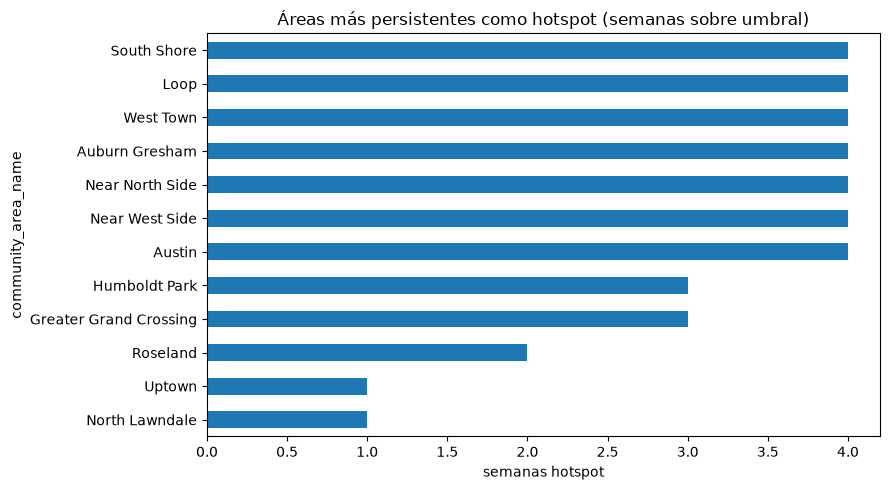

In [5]:
NAMES = q("SELECT community_area, community_area_name FROM warehouse.dim_community_area")

stab = (features.groupby("community_area")
        .agg(semanas_hotspot=("hotspot_observado", "sum"),
             semanas=("hotspot_observado", "size"),
             crime_total=("crime_count", "sum"))
        .reset_index())
display(stab)
stab["pct_semanas"] = (100 * stab.semanas_hotspot / stab.semanas).round(1)
stab = stab.merge(NAMES, on="community_area")
stab = stab.sort_values(["semanas_hotspot", "crime_total"], ascending=False)
display(stab.head(12))

top = stab.head(12).sort_values("semanas_hotspot")
ax = top.plot.barh(x="community_area_name", y="semanas_hotspot",
                   figsize=(9, 5), legend=False,
                   title="Áreas más persistentes como hotspot (semanas sobre umbral)")
ax.set_xlabel("semanas hotspot")
plt.tight_layout()


## 4 · Cruce con DBSCAN: ¿los clusters coinciden con las áreas hotspot?

Comparación de volumen: los clusters más densos (guardados en el notebook
04) vs las áreas con más semanas-hotspot. Sin join espacial (eso pide
geometría; para Nivel 1 basta contrastar listas).


In [7]:
runs = q("SELECT * FROM warehouse.hotspot_runs ORDER BY run_key DESC LIMIT 3")
display(runs)

if len(runs):
    run = runs.iloc[0]
    clusters = q(f"""
        SELECT cluster_label, n_points, centroid_lat, centroid_lon
        FROM warehouse.hotspot_clusters
        WHERE run_key = {int(run.run_key)}
        ORDER BY n_points DESC LIMIT 10
    """)
    display(clusters)
else:
    print("Sin corridas guardadas: corre el notebook 04 (Paso 5) primero.")


,run_key,eps,min_samples,computed_at,n_clusters,n_noise
0,3,200.0,25,2026-10-21 18:25:06.336544+00:00,51,15857
1,2,200.0,25,2026-10-21 18:23:31.504791+00:00,51,15857
2,1,200.0,25,2026-10-20 06:19:05.654975+00:00,51,15857


,cluster_label,n_points,centroid_lat,centroid_lon
0,0,998,41.887979,-87.627714
1,14,171,41.964330,-87.655177
2,10,149,41.747902,-87.603374
3,3,115,41.778373,-87.614966
4,6,109,41.766073,-87.575884
5,2,105,41.903086,-87.630230
6,22,99,41.749874,-87.665491
7,5,94,41.757390,-87.563537
8,4,94,41.868269,-87.625698
9,20,90,41.880187,-87.634399


## 5 · Conclusiones (completar tras ver los outputs)

- ¿Las áreas persistentes (sección 3) coinciden con las densas del
  notebook 03 y los clusters top de la sección 4?
- ¿El umbral q90 deja un % de área-semanas hotspot razonable (~10%)?
- ¿Qué necesitaría el modelo Nivel 2 (Sprint 10) además de esto?
  (targets ya están: `crime_count_next_week`, `hotspot_next_week`)
- ¿Suficiente para el panel "observado" del dashboard?
